# Ejemplo 2 — Visualización alineada de deformaciones y tensiones

Este cuaderno valida el **visualizador base** de estados seccionales:

- gira la sección para dejar la **línea neutra horizontal**;
- alinea la planta, el diagrama de deformaciones y los diagramas de tensiones
  sobre la misma cota vertical `v`;
- representa todos los materiales y distingue los cordones enfundados;
- conserva la evolución completa por fases.

La visualización es una **proyección de un cálculo ya resuelto**. No vuelve a
resolver el equilibrio ni contiene lógica normativa.

```text
ModeloEstructural + HistorialSeccion + proveedor de leyes
                         │
                         ▼
       construir_evolucion_alineada(...)
                         │
                         ▼
            EvolucionAlineadaVista (DTO)
                         │
              ┌──────────┼──────────┐
              ▼          ▼          ▼
           PySide      Web       Notebook
```

## 1. Separación de responsabilidades

| Capa | Responsabilidad en esta prueba |
|---|---|
| `domain/mechanics/alineacion_deformaciones.py` | Rotación mecánica y definición de la línea neutra |
| `domain/mechanics/campo_tensiones.py` | Deformación constitutiva y tensión en una fibra |
| `application/use_cases/visualizar_tensiones.py` | Geometría efectiva, perfiles y DTO portable |
| Este cuaderno | Dibujo con Matplotlib, sustituible por cualquier otra UI |

El contrato de salida contiene mm, tanto por uno y MPa. No contiene píxeles,
colores, objetos Qt ni coordenadas de pantalla.

In [1]:
from __future__ import annotations

import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Polygon

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))

from placas_alveolares.application.dtos.visualizacion_tensiones import (
    AdherenciaVista,
    ComponenteVista,
    FaseAlineadaVista,
    TipoMaterialVista,
)
from placas_alveolares.application.use_cases.visualizar_tensiones import (
    construir_evolucion_alineada,
)
from placas_alveolares.domain.mechanics.analisis_fases import analizar_fases
from placas_alveolares.domain.mechanics.proveedor_leyes_elasticas import (
    ProveedorLeyesElasticas,
)
from placas_alveolares.domain.model.acciones import EsfuerzosInternos
from placas_alveolares.domain.model.fases import Fase
from placas_alveolares.domain.model.geometria import Punto, circulo, rectangulo
from placas_alveolares.domain.model.materiales import (
    AceroPretensado,
    Hormigon,
)
from placas_alveolares.domain.model.modelo import ModeloEstructural
from placas_alveolares.domain.model.operaciones import PretensadoPorTension
from placas_alveolares.domain.model.seccion import (
    ComponenteSeccion,
    CondicionAdherencia,
    Seccion,
)
from placas_alveolares.domain.model.tiempo import Tiempo
from placas_alveolares.domain.numerics import Newton, OpcionesNewton
from placas_alveolares.domain.state.operaciones import (
    AdherirComponente,
    AsignarPretensado,
)

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 120,
        "axes.grid": True,
        "grid.alpha": 0.20,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 9,
    }
)

## 2. Sección de prueba

La sección combina dos materiales:

- hormigón;
- tres cordones de pretensado, inicialmente enfundados.

Los cordones declaran al hormigón como anfitrión, por lo que la malla efectiva
del hormigón descuenta sus huecos. La flexión biaxial de las fases de carga hará
que la línea neutra no sea horizontal en los ejes originales.

In [2]:
ANCHO = 500.0
ALTO = 700.0
HORMIGON = Hormigon(fck=40.0, fcm=48.0, ecm=35_000.0)
ACERO_PRETENSADO = AceroPretensado(fpk=1_860.0, ep=195_000.0)

COMPONENTES = (
    ComponenteSeccion(
        id="hormigon",
        geometria=rectangulo(ANCHO, ALTO, z_base=-ALTO / 2.0),
        material=HORMIGON,
    ),
    ComponenteSeccion(
        id="tendon-izq",
        geometria=circulo(Punto(y=-140.0, z=-250.0), radio=15.0),
        material=ACERO_PRETENSADO,
        adherencia=CondicionAdherencia.ENFUNDADO,
        componente_anfitrion_id="hormigon",
    ),
    ComponenteSeccion(
        id="tendon-centro",
        geometria=circulo(Punto(y=0.0, z=-250.0), radio=15.0),
        material=ACERO_PRETENSADO,
        adherencia=CondicionAdherencia.ENFUNDADO,
        componente_anfitrion_id="hormigon",
    ),
    ComponenteSeccion(
        id="tendon-der",
        geometria=circulo(Punto(y=140.0, z=-250.0), radio=15.0),
        material=ACERO_PRETENSADO,
        adherencia=CondicionAdherencia.ENFUNDADO,
        componente_anfitrion_id="hormigon",
    ),
)

## 3. Fases y cálculo

La secuencia es:

1. **Tesado de cordones**: los tres cordones reciben una tensión inicial de
   1 250 MPa, pero siguen enfundados y no contribuyen al equilibrio.
2. **Transferencia al hormigón**: a 1 día se adhieren los cordones. La fuerza de
   pretensado pasa al hormigón y se resuelve el equilibrio sin acciones
   externas.
3. **Carga instantánea I**: se aplican
   $M_y=80\ \mathrm{kN\,m}$ y $M_z=20\ \mathrm{kN\,m}$.
4. **Carga instantánea II**: se añaden otros
   $\Delta M_y=220\ \mathrm{kN\,m}$ y
   $\Delta M_z=80\ \mathrm{kN\,m}$. Como las acciones de una fase son
   totales, esta fase declara $M_y=300\ \mathrm{kN\,m}$ y
   $M_z=100\ \mathrm{kN\,m}$.

El proveedor es elástico para mantener el ejemplo simple. La visualización
funciona igual con leyes normativas inyectadas.

In [3]:
TENDONES = ("tendon-izq", "tendon-centro", "tendon-der")
TENSION_TESADO = 1_250.0

CARGA_INSTANTANEA_I = EsfuerzosInternos(m_y=80.0e6, m_z=20.0e6)
CARGA_INSTANTANEA_II = EsfuerzosInternos(m_y=300.0e6, m_z=100.0e6)

MODELO = ModeloEstructural(
    seccion=Seccion(componentes=COMPONENTES),
    fases=(
        Fase(
            indice=0,
            tiempo_inicio=Tiempo(0.0),
            tiempo_fin=Tiempo(0.0),
            resolver_equilibrio=False,
            operaciones=tuple(
                AsignarPretensado(
                    tendon,
                    PretensadoPorTension(TENSION_TESADO),
                )
                for tendon in TENDONES
            ),
            nombre="Tesado de cordones",
        ),
        Fase(
            indice=1,
            tiempo_inicio=Tiempo(0.0),
            tiempo_fin=Tiempo(1.0),
            operaciones=tuple(
                AdherirComponente(tendon) for tendon in TENDONES
            ),
            nombre="Transferencia al hormigón",
        ),
        Fase(
            indice=2,
            tiempo_inicio=Tiempo(1.0),
            tiempo_fin=Tiempo(1.0),
            acciones=CARGA_INSTANTANEA_I,
            nombre="Carga instantánea I",
        ),
        Fase(
            indice=3,
            tiempo_inicio=Tiempo(1.0),
            tiempo_fin=Tiempo(1.0),
            acciones=CARGA_INSTANTANEA_II,
            nombre="Carga instantánea II",
        ),
    ),
    fase_activa=3,
)

PROVEEDOR = ProveedorLeyesElasticas()
SOLVER = Newton(
    OpcionesNewton(
        tolerancia_residuo=1.0e-9,
        tolerancia_residuo_relativa=1.0e-9,
        max_iteraciones=100,
    )
)
HISTORIAL = analizar_fases(MODELO, PROVEEDOR, SOLVER)
EVOLUCION = construir_evolucion_alineada(
    MODELO,
    HISTORIAL,
    PROVEEDOR,
    muestras_perfil=241,
)

print("Estado final de deformaciones y tensiones por fase")
print("=" * 118)
for fase, estado in zip(EVOLUCION.fases, HISTORIAL.estados, strict=True):
    plano = estado.plano_comun
    equilibrio = "sí" if fase.equilibrio_resuelto else "no"
    print(
        f"Fase {fase.indice} · {fase.nombre} · "
        f"t={fase.tiempo_fin_dias:g} d · equilibrio={equilibrio}"
    )
    print(
        f"  plano común final: ε0={plano.eps0 * 1.0e3:+.6f} ‰, "
        f"κy={plano.kappa_y:+.6e} mm⁻¹, "
        f"κz={plano.kappa_z:+.6e} mm⁻¹"
    )
    for componente in fase.componentes:
        muestras = tuple(
            muestra
            for tramo in componente.perfil.tramos
            for muestra in tramo.muestras
        )
        if not muestras:
            print(f"    {componente.componente_id:<20} sin perfil")
            continue
        deformaciones = [muestra.deformacion * 1.0e3 for muestra in muestras]
        tensiones = [muestra.tension for muestra in muestras]
        print(
            f"    {componente.componente_id:<20} "
            f"{componente.adherencia.value:<9} "
            f"ε=[{min(deformaciones):+8.4f}, {max(deformaciones):+8.4f}] ‰  "
            f"σ=[{min(tensiones):+9.3f}, {max(tensiones):+9.3f}] MPa"
        )
    print("-" * 118)

print(
    "Segunda carga: totales "
    f"M_y={CARGA_INSTANTANEA_II.m_y / 1.0e6:.0f} kN·m, "
    f"M_z={CARGA_INSTANTANEA_II.m_z / 1.0e6:.0f} kN·m; "
    f"incremento M_y="
    f"{(CARGA_INSTANTANEA_II.m_y - CARGA_INSTANTANEA_I.m_y) / 1.0e6:.0f} "
    "kN·m, "
    f"M_z="
    f"{(CARGA_INSTANTANEA_II.m_z - CARGA_INSTANTANEA_I.m_z) / 1.0e6:.0f} "
    "kN·m."
)


Estado final de deformaciones y tensiones por fase
Fase 0 · Tesado de cordones · t=0 d · equilibrio=no
  plano común final: ε0=+0.000000 ‰, κy=+0.000000e+00 mm⁻¹, κz=+0.000000e+00 mm⁻¹
    hormigon             adherido  ε=[ +0.0000,  +0.0000] ‰  σ=[   +0.000,    +0.000] MPa
    tendon-izq           enfundado ε=[ +6.4103,  +6.4103] ‰  σ=[+1250.000, +1250.000] MPa
    tendon-centro        enfundado ε=[ +6.4103,  +6.4103] ‰  σ=[+1250.000, +1250.000] MPa
    tendon-der           enfundado ε=[ +6.4103,  +6.4103] ‰  σ=[+1250.000, +1250.000] MPa
----------------------------------------------------------------------------------------------------------------------
Fase 1 · Transferencia al hormigón · t=1 d · equilibrio=sí
  plano común final: ε0=-0.197385 ‰, κy=+1.208433e-06 mm⁻¹, κz=+4.915697e-23 mm⁻¹
    hormigon             adherido  ε=[ -0.6203,  +0.2256] ‰  σ=[  -21.712,    +7.895] MPa
    tendon-izq           adherido  ε=[ +5.8926,  +5.9289] ‰  σ=[+1149.064, +1156.134] MPa
    tendon-cent

## 4. Cómo se alinea la línea neutra

Para el plano común

$$\varepsilon(y,z)=\varepsilon_0+\kappa_y z-\kappa_z y,$$

la curvatura resultante es $\kappa=\sqrt{\kappa_y^2+\kappa_z^2}$. El sistema
girado se define con:

$$u=\frac{\kappa_y y+\kappa_z z}{\kappa}, \qquad
q=\frac{-\kappa_z y+\kappa_y z}{\kappa}.$$

Trasladando el origen a la línea neutra, $v=q+\varepsilon_0/\kappa$, resulta

$$\boxed{\varepsilon=\kappa\,v}.$$

Por tanto la línea neutra queda en $v=0$ y los tres paneles pueden compartir la
misma escala vertical. Si $\kappa\approx 0$ no existe dirección única de línea
neutra: se conserva la orientación original y el DTO lo indica con
`linea_neutra_definida = False`.

Cada componente se muestrea en la vertical que pasa por el centroide de su
geometría efectiva. Los huecos interrumpen el perfil en tramos, de modo que no
se dibuja tensión dentro de un alveolo o de un cordón embebido.

## 5. Utilidades de dibujo

El DTO no impone ninguna estética. Estas funciones son el **adaptador de
presentación** del cuaderno y podrían sustituirse por un widget Qt, un canvas
web o un exportador SVG sin tocar el núcleo.

In [4]:
COLORES = {
    TipoMaterialVista.HORMIGON: "#cfcfcf",
    TipoMaterialVista.ACERO_PRETENSADO: "#2563eb",
}
BORDES = {
    TipoMaterialVista.HORMIGON: "#4b5563",
    TipoMaterialVista.ACERO_PRETENSADO: "#1e3a8a",
}
ETIQUETAS = {
    TipoMaterialVista.HORMIGON: "Hormigón",
    TipoMaterialVista.ACERO_PRETENSADO: "Pretensado",
}


def color_componente(componente: ComponenteVista) -> str:
    """Color de relleno; aclara los cordones enfundados."""
    if componente.adherencia is AdherenciaVista.ENFUNDADO:
        return "#93c5fd"
    return COLORES[componente.tipo_material]


def dibujar_seccion(ax: plt.Axes, fase: FaseAlineadaVista) -> None:
    """Dibuja la planta girada con sus huecos y materiales."""
    for componente in fase.componentes:
        zorder = (
            3
            if componente.tipo_material is not TipoMaterialVista.HORMIGON
            else 2
        )
        ax.add_patch(
            Polygon(
                [(p.u, p.v) for p in componente.geometria.exterior.puntos],
                closed=True,
                facecolor=color_componente(componente),
                edgecolor=BORDES[componente.tipo_material],
                linewidth=0.8,
                zorder=zorder,
            )
        )
        for hueco in componente.geometria.huecos:
            ax.add_patch(
                Polygon(
                    [(p.u, p.v) for p in hueco.puntos],
                    closed=True,
                    facecolor="white",
                    edgecolor="white",
                    linewidth=0.5,
                    zorder=2.5,
                )
            )
    ax.set_aspect("equal")
    ax.set_xlabel("u (mm)")


def dibujar_deformaciones(ax: plt.Axes, fase: FaseAlineadaVista) -> None:
    """Dibuja el plano común y las deformaciones con relleno translúcido."""
    muestra_a, muestra_b = fase.deformacion_comun
    x_comun = [
        muestra_a.deformacion * 1000.0,
        muestra_b.deformacion * 1000.0,
    ]
    y_comun = [muestra_a.v, muestra_b.v]
    ax.fill_betweenx(
        y_comun,
        0.0,
        x_comun,
        color="#111827",
        alpha=0.10,
        linewidth=0.0,
        zorder=1,
    )
    ax.plot(
        x_comun,
        y_comun,
        color="#111827",
        linewidth=2.2,
        label="Plano común",
        zorder=2,
    )
    for componente in fase.componentes:
        for tramo in componente.perfil.tramos:
            x = [m.deformacion * 1000.0 for m in tramo.muestras]
            y = [m.v for m in tramo.muestras]
            ax.fill_betweenx(
                y,
                0.0,
                x,
                color=COLORES[componente.tipo_material],
                alpha=0.16,
                linewidth=0.0,
                zorder=1,
            )
            ax.plot(
                x,
                y,
                color=COLORES[componente.tipo_material],
                linewidth=1.0,
                linestyle="--",
                alpha=0.85,
                zorder=2,
            )
    ax.axvline(0.0, color="0.3", linewidth=0.8)
    ax.set_xlabel("ε (‰)")


def dibujar_tensiones(
    ax: plt.Axes,
    fase: FaseAlineadaVista,
    tipos: tuple[TipoMaterialVista, ...] | None = None,
    *,
    etiquetar: bool = False,
) -> None:
    """Dibuja perfiles de tensión con área translúcida hasta el eje cero."""
    for componente in fase.componentes:
        if tipos is not None and componente.tipo_material not in tipos:
            continue
        for tramo in componente.perfil.tramos:
            x = [m.tension for m in tramo.muestras]
            y = [m.v for m in tramo.muestras]
            ax.fill_betweenx(
                y,
                0.0,
                x,
                color=COLORES[componente.tipo_material],
                alpha=0.22,
                linewidth=0.0,
                zorder=1,
            )
            ax.plot(
                x,
                y,
                color=COLORES[componente.tipo_material],
                linewidth=1.7,
                linestyle=(
                    "--"
                    if componente.adherencia is AdherenciaVista.ENFUNDADO
                    else "-"
                ),
                label=componente.componente_id if etiquetar else None,
                zorder=2,
            )
    ax.axvline(0.0, color="0.3", linewidth=0.8)
    ax.set_xlabel("σ (MPa)")


def limites_verticales() -> tuple[float, float]:
    """Rango vertical común de todas las fases, con margen."""
    rango = EVOLUCION.limites_globales.vertical
    margen = 0.04 * rango.amplitud
    return rango.minimo - margen, rango.maximo + margen


def limite_horizontal(rango) -> float:
    """Semiamplitud simétrica para comparar magnitudes entre fases."""
    return max(abs(rango.minimo), abs(rango.maximo), 1.0e-12) * 1.15


def limite_tensiones(
    tipos: tuple[TipoMaterialVista, ...],
) -> float:
    """Escala común de un grupo de materiales a lo largo de todas las fases."""
    valores = [
        muestra.tension
        for fase in EVOLUCION.fases
        for componente in fase.componentes
        if componente.tipo_material in tipos
        for tramo in componente.perfil.tramos
        for muestra in tramo.muestras
    ]
    limite = max((abs(valor) for valor in valores), default=1.0)
    return limite * 1.15


Y_LIM = limites_verticales()
EPS_LIM = limite_horizontal(EVOLUCION.limites_globales.deformacion) * 1000.0
SIGMA_LIM_HORMIGON = limite_tensiones((TipoMaterialVista.HORMIGON,))
SIGMA_LIM_ACTIVO = limite_tensiones((TipoMaterialVista.ACERO_PRETENSADO,))

## 6. Evolución completa

Cada fila es una fase y todas las columnas comparten la cota `v`. La línea
neutra se dibuja en `v = 0` cuando existe. Los perfiles discontinuos
corresponden a componentes **enfundados**: se muestra su tensión propia, pero
no contribuyen al equilibrio de la sección.

Hormigón y pretensado tienen **escalas independientes**. Si se compartiera una
única escala, los aproximadamente 1 100 MPa del pretensado dejarían invisible
la respuesta del hormigón. Las áreas se rellenan con transparencia hasta el eje
cero para leer la forma del diagrama, no solo su contorno.

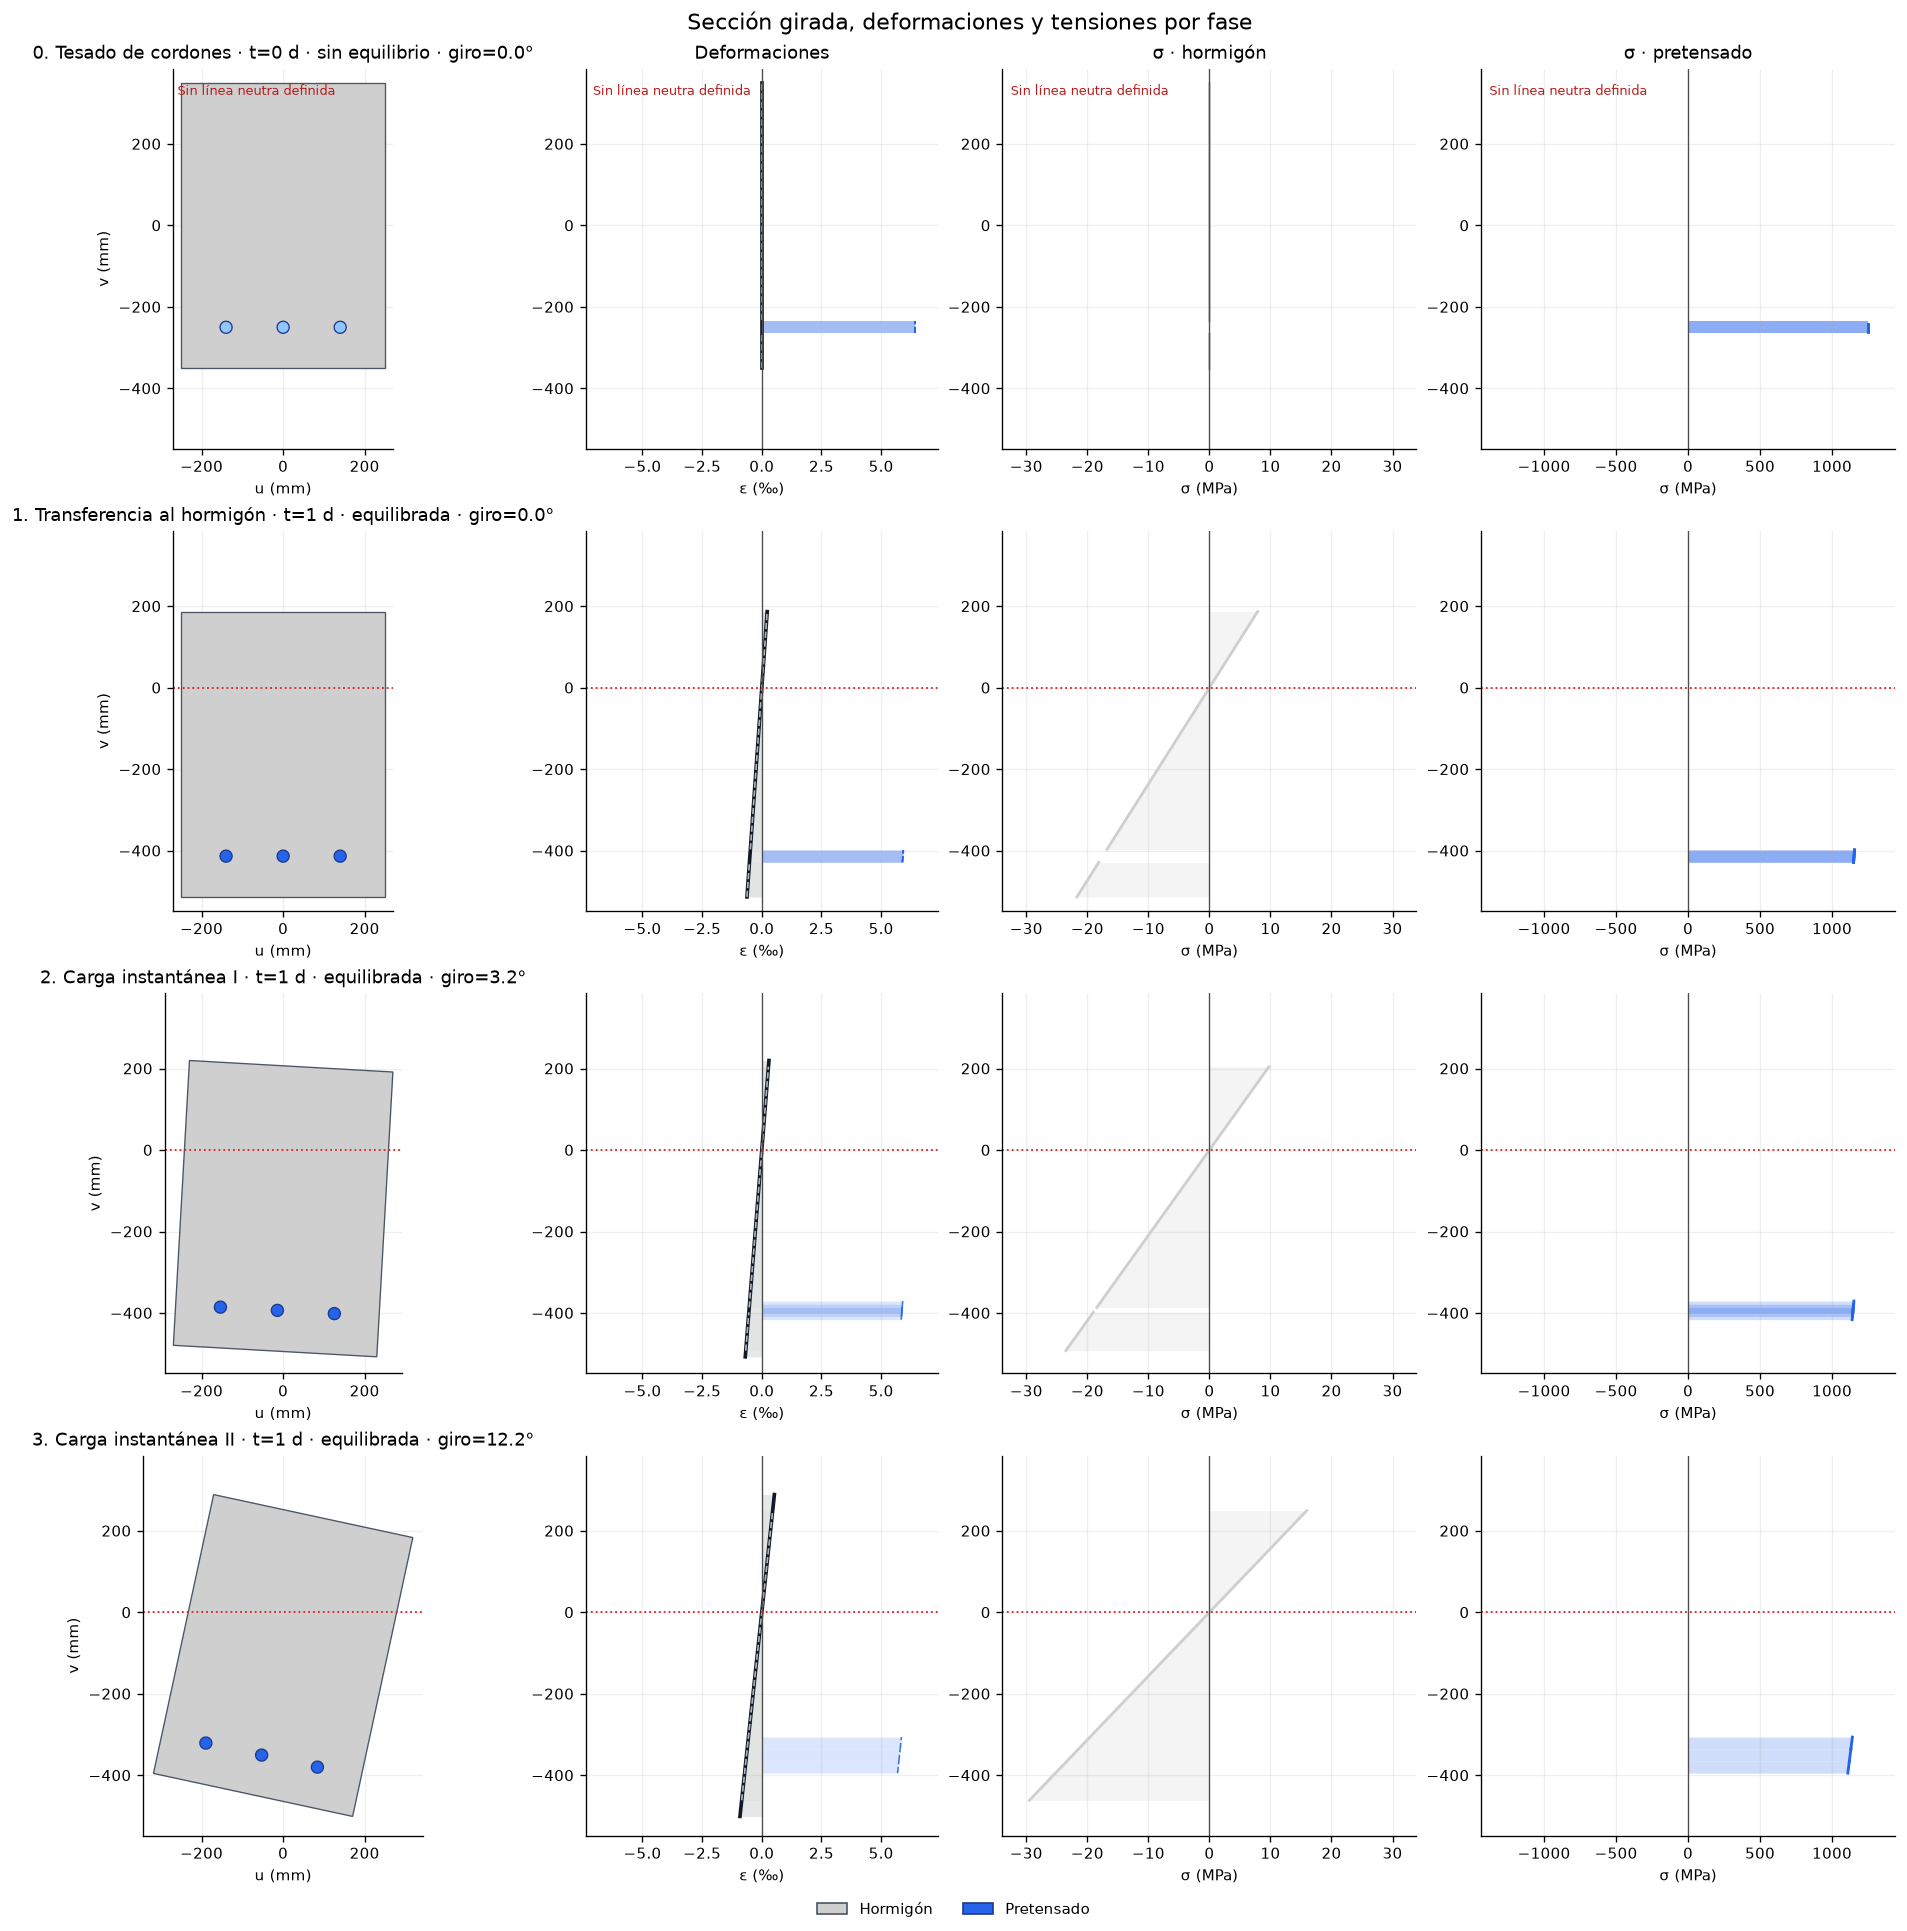

In [5]:
fig, ejes = plt.subplots(
    len(EVOLUCION.fases),
    4,
    figsize=(15.5, 4.0 * len(EVOLUCION.fases)),
    constrained_layout=True,
    gridspec_kw={"width_ratios": (1.15, 0.85, 1.0, 1.0)},
)
for fila, fase in enumerate(EVOLUCION.fases):
    (
        ax_seccion,
        ax_eps,
        ax_sigma_hormigon,
        ax_sigma_activo,
    ) = ejes[fila]
    dibujar_seccion(ax_seccion, fase)
    dibujar_deformaciones(ax_eps, fase)
    dibujar_tensiones(
        ax_sigma_hormigon,
        fase,
        (TipoMaterialVista.HORMIGON,),
    )
    dibujar_tensiones(
        ax_sigma_activo,
        fase,
        (TipoMaterialVista.ACERO_PRETENSADO,),
        etiquetar=fila == 0,
    )

    cotas_u = [
        punto.u
        for componente in fase.componentes
        for punto in componente.geometria.exterior.puntos
    ]
    margen_u = 0.04 * (max(cotas_u) - min(cotas_u))
    ax_seccion.set_xlim(min(cotas_u) - margen_u, max(cotas_u) + margen_u)

    for ax in (
        ax_seccion,
        ax_eps,
        ax_sigma_hormigon,
        ax_sigma_activo,
    ):
        ax.set_ylim(Y_LIM)
        if fase.linea_neutra_definida:
            ax.axhline(0.0, color="#dc2626", linewidth=1.1, linestyle=":")
        else:
            ax.text(
                0.02,
                0.96,
                "Sin línea neutra definida",
                transform=ax.transAxes,
                va="top",
                fontsize=8,
                color="#b91c1c",
            )
    ax_eps.set_xlim(-EPS_LIM, EPS_LIM)
    ax_sigma_hormigon.set_xlim(-SIGMA_LIM_HORMIGON, SIGMA_LIM_HORMIGON)
    ax_sigma_activo.set_xlim(-SIGMA_LIM_ACTIVO, SIGMA_LIM_ACTIVO)
    ax_seccion.set_ylabel("v (mm)")

    estado = "equilibrada" if fase.equilibrio_resuelto else "sin equilibrio"
    ax_seccion.set_title(
        f"{fase.indice}. {fase.nombre} · t={fase.tiempo_fin_dias:g} d · "
        f"{estado} · giro={math.degrees(fase.angulo_radianes):.1f}°"
    )
    if fila == 0:
        ax_eps.set_title("Deformaciones")
        ax_sigma_hormigon.set_title("σ · hormigón")
        ax_sigma_activo.set_title("σ · pretensado")

fig.legend(
    handles=[
        Patch(
            facecolor=COLORES[tipo],
            edgecolor=BORDES[tipo],
            label=ETIQUETAS[tipo],
        )
        for tipo in (
            TipoMaterialVista.HORMIGON,
            TipoMaterialVista.ACERO_PRETENSADO,
        )
    ],
    loc="outside lower center",
    ncol=2,
    frameon=False,
)
fig.suptitle(
    "Sección girada, deformaciones y tensiones por fase",
    fontsize=13,
)
plt.show()


## 7. Detalle de una fase: una escala por material

La escala se separa en dos gráficos de tensión: hormigón y pretensado. Así se
aprecian las formas reales de cada material. La cota `v`, la línea neutra y el
relleno translúcido se mantienen en todos los paneles.

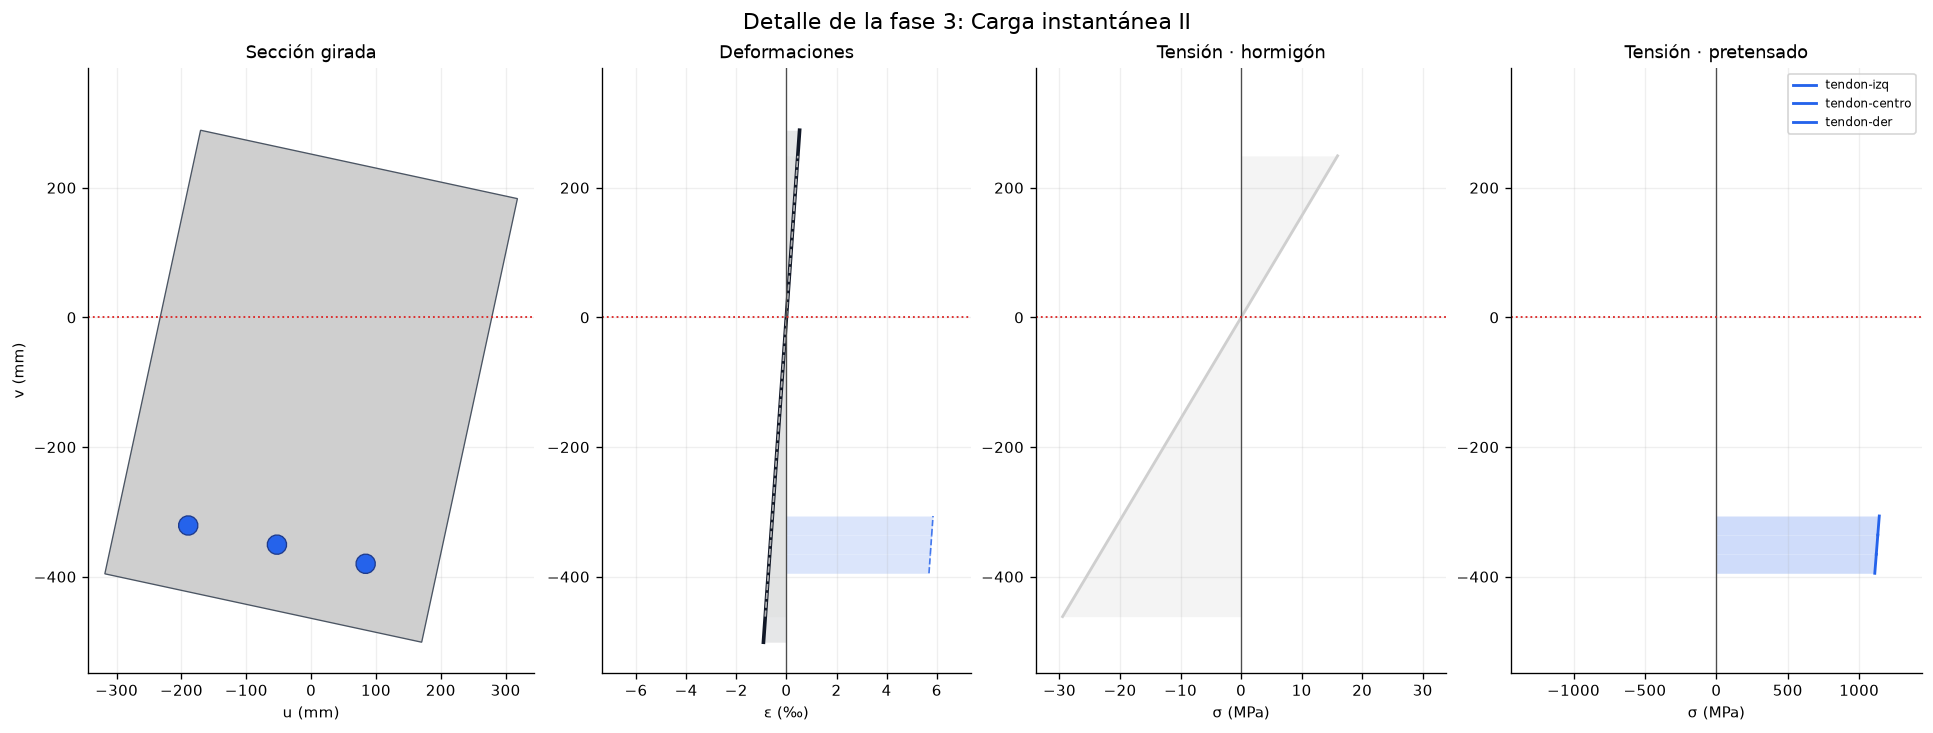

In [6]:
fase_detalle = EVOLUCION.fases[-1]
fig, ejes = plt.subplots(
    1,
    4,
    figsize=(16, 6),
    constrained_layout=True,
    gridspec_kw={"width_ratios": (1.1, 0.9, 1.0, 1.0)},
)
(
    ax_seccion,
    ax_eps,
    ax_sigma_hormigon,
    ax_sigma_activo,
) = ejes
dibujar_seccion(ax_seccion, fase_detalle)
dibujar_deformaciones(ax_eps, fase_detalle)
dibujar_tensiones(
    ax_sigma_hormigon,
    fase_detalle,
    (TipoMaterialVista.HORMIGON,),
)
dibujar_tensiones(
    ax_sigma_activo,
    fase_detalle,
    (TipoMaterialVista.ACERO_PRETENSADO,),
    etiquetar=True,
)

cotas_u = [
    punto.u
    for componente in fase_detalle.componentes
    for punto in componente.geometria.exterior.puntos
]
margen_u = 0.04 * (max(cotas_u) - min(cotas_u))
ax_seccion.set_xlim(min(cotas_u) - margen_u, max(cotas_u) + margen_u)

for ax in ejes:
    ax.set_ylim(Y_LIM)
    if fase_detalle.linea_neutra_definida:
        ax.axhline(0.0, color="#dc2626", linewidth=1.1, linestyle=":")
ax_eps.set_xlim(-EPS_LIM, EPS_LIM)
ax_sigma_hormigon.set_xlim(-SIGMA_LIM_HORMIGON, SIGMA_LIM_HORMIGON)
ax_sigma_activo.set_xlim(-SIGMA_LIM_ACTIVO, SIGMA_LIM_ACTIVO)
ax_seccion.set_ylabel("v (mm)")
ax_seccion.set_title("Sección girada")
ax_eps.set_title("Deformaciones")
ax_sigma_hormigon.set_title("Tensión · hormigón")
ax_sigma_activo.set_title("Tensión · pretensado")
ax_sigma_activo.legend(fontsize=7, loc="best")
fig.suptitle(
    f"Detalle de la fase {fase_detalle.indice}: {fase_detalle.nombre}",
    fontsize=13,
)
plt.show()


## 8. Comprobaciones

Las aserciones verifican las invariantes del contrato sin depender del dibujo:

- todas las fases están presentes y conservan su estado de equilibrio;
- la deformación común cumple $\varepsilon=\kappa v$;
- la línea neutra está en `v = 0` cuando está definida;
- los cordones tesados conservan su tensión antes de adherirse;
- el hormigón tiene huecos geométricos y su perfil se interrumpe;
- la sección solo contiene hormigón y pretensado;
- el hormigón descuenta únicamente los huecos de los tres cordones;
- la segunda carga contiene el incremento previsto sobre la primera.

In [7]:
assert [fase.indice for fase in EVOLUCION.fases] == [0, 1, 2, 3]
assert EVOLUCION.version_formato == 1
assert not EVOLUCION.fases[0].equilibrio_resuelto
assert all(fase.equilibrio_resuelto for fase in EVOLUCION.fases[1:])
assert not EVOLUCION.fases[0].linea_neutra_definida
assert all(fase.linea_neutra_definida for fase in EVOLUCION.fases[1:])

for fase in EVOLUCION.fases:
    assert fase.limites.vertical.minimo <= fase.limites.vertical.maximo
    for muestra in fase.deformacion_comun:
        if fase.linea_neutra_definida:
            assert math.isclose(
                muestra.deformacion,
                fase.curvatura * muestra.v,
                rel_tol=1.0e-12,
                abs_tol=1.0e-15,
            )

fase_tesado = EVOLUCION.fases[0]
tendones_tesado = [
    componente
    for componente in fase_tesado.componentes
    if componente.tipo_material is TipoMaterialVista.ACERO_PRETENSADO
]
assert len(tendones_tesado) == len(TENDONES)
assert all(
    componente.adherencia is AdherenciaVista.ENFUNDADO
    for componente in tendones_tesado
)
assert all(
    math.isclose(muestra.tension, TENSION_TESADO, rel_tol=1.0e-12)
    for componente in tendones_tesado
    for tramo in componente.perfil.tramos
    for muestra in tramo.muestras
)

fase_transferencia = EVOLUCION.fases[1]
tendones_transferencia = [
    componente
    for componente in fase_transferencia.componentes
    if componente.tipo_material is TipoMaterialVista.ACERO_PRETENSADO
]
assert len(tendones_transferencia) == len(TENDONES)
assert all(
    componente.adherencia is AdherenciaVista.ADHERIDO
    for componente in tendones_transferencia
)
for fase in EVOLUCION.fases:
    assert len(fase.componentes) == 1 + len(TENDONES)
    assert all(
        componente.tipo_material
        in (
            TipoMaterialVista.HORMIGON,
            TipoMaterialVista.ACERO_PRETENSADO,
        )
        for componente in fase.componentes
    )
    hormigon = next(
        componente
        for componente in fase.componentes
        if componente.tipo_material is TipoMaterialVista.HORMIGON
    )
    assert len(hormigon.geometria.huecos) == len(TENDONES)

assert MODELO.fases[3].acciones.m_y - MODELO.fases[2].acciones.m_y == 220.0e6
assert MODELO.fases[3].acciones.m_z - MODELO.fases[2].acciones.m_z == 80.0e6
print("Todas las invariantes del modelo de visualización se cumplen.")


Todas las invariantes del modelo de visualización se cumplen.


## 9. Alcance y siguientes pasos

Esta primera versión demuestra el contrato y el dibujo. Limitaciones conocidas:

- el perfil se extrae en la vertical del centroide de cada componente: no se
  representa el campo completo `σ(u, v)`, por lo que las diferencias entre
  verticales y las posibles envolventes transversales quedan para una versión
  posterior;
- la evolución es discreta entre fases: no interpola dentro de una fase;
- el DTO aún no incluye un serializador JSON versionado;
- la UI PySide, la reproducción animada y la exportación SVG/PNG quedan como
  adaptadores posteriores sobre el mismo contrato.

Para ejecutar el cuaderno:

```powershell
.venv\Scripts\activate
pip install -e ".[dev,notebooks]"
jupyter nbconvert --execute --to notebook --inplace notebooks\ejemplo_2_visualizacion_tensiones.ipynb
```